# How strong should a black-and-white video grade be?

Watch the edge of the grinder and the dark coffee beans at the same instant in three versions of a shot. How far can you take the look before you lose a detail you care about? Run all cells to render your own comparison sheet and check that your editing pipeline reads a downloaded 3D LUT correctly. The sample and LUT are public. You can run the notebook locally with Jupyter, Pillow and FFmpeg, or open it in Colab.

The LUT comes from the B&W preset in [Valmera's free browser color grader](https://valmera.io/tools/color-grade-video?utm_source=github&utm_medium=notebook&utm_campaign=color_grade). Select the coffee sample to try a different exposure, contrast or temperature. Download the selected look to repeat this exercise with your own grade.

In [1]:
from io import BytesIO
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlopen
import hashlib
import shutil
import subprocess

from IPython.display import display
from PIL import Image, ImageChops, ImageDraw

ffmpeg = shutil.which("ffmpeg")
if ffmpeg is None:
    import imageio_ffmpeg  # pip install imageio-ffmpeg when a system FFmpeg is unavailable
    ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()

workspace = TemporaryDirectory()
work = Path(workspace.name)
source = "https://valmera.io/examples/color-grade/"
files = {
    "coffee.webm": "44d8eece4b5874f6b0e5fff5e8212ad649a6f0968afcf2503efe06e48b2fab67",
    "rgb-swatches.png": "207a40925de40d8903fe9624016739e4747d4fd21848fc02dd74e412889d7a04",
    "rgb-swatches-mono.png": "7e3c693bcad32e6caf3ee636937c034542c1322b8773116f9adbf7e18f0a0f3c",
    "valmera-mono.cube": "9485fdd355591ae676213ec4b11e8abdcb39f86475a9e8b586a3e424736b05bb",
}
for name, expected in files.items():
    with urlopen(source + name, timeout=30) as response:
        payload = response.read()
    if hashlib.sha256(payload).hexdigest() != expected:
        raise ValueError(f"The published fixture changed: {name}")
    (work / name).write_bytes(payload)
print("Verified all four reference files.")

Verified all four reference files.


## Check the transform on known colors

Apply the LUT to the RGB chart before judging the moving shot. Green should render much brighter than red, and blue should go black. The table samples patch centers. The difference check compares the whole image to the published FFmpeg reference, including patch edges.

In [2]:
def frame(source_file, filters=None, seconds=None):
    args = [ffmpeg, "-hide_banner", "-loglevel", "error", "-i", str(source_file)]
    if seconds is not None:
        args += ["-ss", str(seconds)]
    if filters:
        args += ["-vf", filters]
    args += ["-frames:v", "1", "-threads", "1", "-f", "image2pipe", "-c:v", "png", "pipe:1"]
    png = subprocess.check_output(args, cwd=work)
    return Image.open(BytesIO(png)).convert("RGB")

grade = "format=rgb24,lut3d=file=valmera-mono.cube:interp=tetrahedral"
chart = frame("rgb-swatches.png", grade)
with Image.open(work / "rgb-swatches-mono.png") as reference:
    difference = ImageChops.difference(chart, reference.convert("RGB"))
for index, name in enumerate(["red", "green", "blue", "cyan", "magenta", "yellow"]):
    xy = ((2 * index + 1) * chart.width // 12, chart.height // 4)
    print(f"{name:8s} {chart.getpixel(xy)}")
print("Largest absolute difference per RGB channel:", [hi for lo, hi in difference.getextrema()])

red      (42, 42, 42)
green    (189, 189, 189)
blue     (0, 0, 0)
cyan     (212, 212, 212)
magenta  (63, 63, 63)
yellow   (253, 253, 253)
Largest absolute difference per RGB channel: [0, 0, 0]


## Compare one source frame at three strengths

Decode the coffee shot once. Use that same RGB frame for every version. The middle panel mixes the original and fully graded RGB values halfway. This is a display-space mix you can reproduce independently. In particular, it does not simulate a camera exposure change.

Choose a time inside the sample and set the middle mix anywhere from 0 to 1.

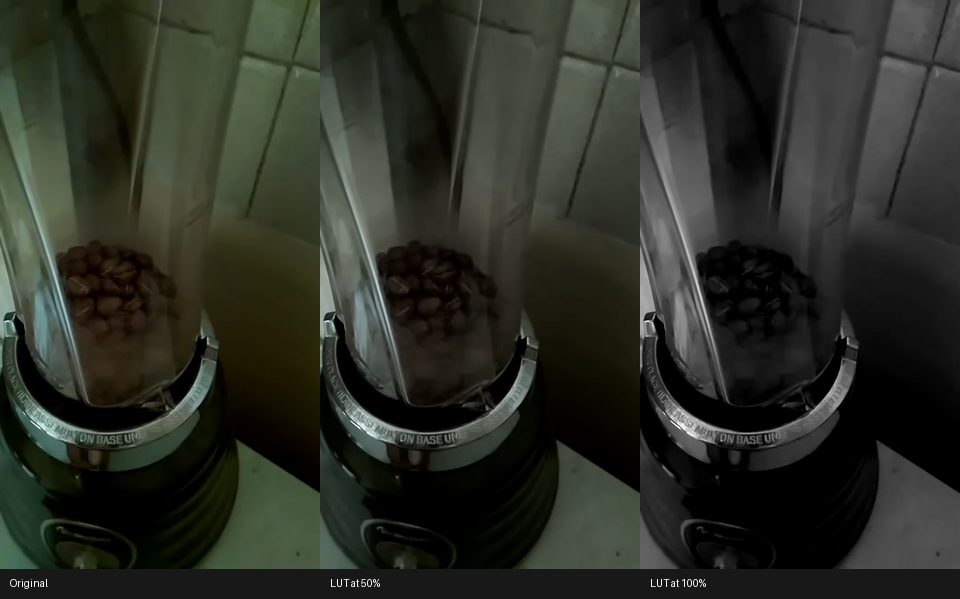

In [3]:
time_seconds = 2.0
middle_mix = 0.5
assert 0 <= middle_mix <= 1
original = frame("coffee.webm", "format=rgb24", seconds=time_seconds)
original.save(work / "original.png")
graded = frame("original.png", grade)
middle = Image.blend(original, graded, middle_mix)
panels = [("Original", original), (f"LUT at {middle_mix:.0%}", middle), ("LUT at 100%", graded)]
width = 320
height = round(original.height * width / original.width)
sheet = Image.new("RGB", (width * len(panels), height + 30), "#181818")
draw = ImageDraw.Draw(sheet)
for index, (label, picture) in enumerate(panels):
    x = index * width
    sheet.paste(picture.resize((width, height), Image.Resampling.LANCZOS), (x, 0))
    draw.text((x + 10, height + 8), label, fill="white")
display(sheet)

## Measure what happened to the dark and bright areas

For each full-size frame, count pixels at either end of its 8-bit luma histogram. A rise in near-black pixels tells you where to look for lost separation. Zoom in on the shot before deciding whether those pixels represent crushed texture or a subject that should be dark. The 0–7 and 248–255 ranges below include both endpoints.

In [4]:
for label, picture in panels:
    histogram = picture.convert("L").histogram()
    pixels = picture.width * picture.height
    dark = 100 * sum(histogram[:8]) / pixels
    bright = 100 * sum(histogram[248:]) / pixels
    print(f"{label:13s}  near black {dark:5.1f}%   near white {bright:5.1f}%")

Original       near black  11.4%   near white   0.0%
LUT at 50%     near black  16.7%   near white   0.0%
LUT at 100%    near black  24.0%   near white   0.0%


**Try your own look.** Keep the reference LUT in place for the chart check. Save a second LUT as `my-look.cube` beside your notebook (in Colab, use the Files pane). After the reference chart cell runs, copy the second LUT into the temporary working folder with `shutil.copyfile("my-look.cube", work / "my-look.cube")`. Set `grade = "format=rgb24,lut3d=file=my-look.cube:interp=tetrahedral"`, then rerun only the coffee-frame and histogram cells. Local Jupyter keeps your custom LUT on your computer. Colab runs on Google's servers.

For camera log or HDR material, first put the footage into the display space expected by the creative LUT. This demonstration uses a decoded SDR frame. An export check should also cover motion, timing and audio. The [recorded export comparison](https://github.com/ABO3SKRALMASAOODI/valmera-mcp/blob/main/docs/COLOR-GRADE-EXAMPLE.md) includes the original video, browser export and frame counts.

**Footage credit.** PetrohsW, [*MoliendoCafeEnLicuadora ohs02.webm*](https://commons.wikimedia.org/wiki/File:MoliendoCafeEnLicuadora_ohs02.webm), [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/). The comparison sheet extracts, grades, resizes and labels one frame. The adapted sheet is available under the same license.